# USED SMARTPHONES PRICES PREDICTION USING PYTHON

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:
def normalized_to_real_price(normalized_price):
    """Convert a natural-log price back to the original price in euros.

    This dataset's normalized price values are on a natural-log scale, so the
    inverse transformation is exp(value). The dataset documentation describes
    prices in euros; this does not convert currencies.
    """
    return float(np.exp(normalized_price))


## 2. Load the dataset

In [4]:
used_phones = pd.read_csv("used_device_data.csv")

used_phones.head()


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [5]:
used_phones.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   device_brand           3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   rear_camera_mp         3275 non-null   float64
 6   front_camera_mp        3452 non-null   float64
 7   internal_memory        3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float64
dtypes: f

In [20]:
used_phones.shape

(3454, 15)

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
used_phones.describe(include="all")


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
count,3454,3454,3454.000000,3454,3454,3275.000000,3452.000000,3450.000000,3450.000000,3448.000000,3447.000000,3454.000000,3454.000000,3454.000000,3454.000000
unique,34,4,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Others,Android,NaN,yes,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,502,3214,NaN,2335,3302,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,13.713115,NaN,NaN,9.460208,6.554229,54.573099,4.036122,3133.402697,182.751871,2015.965258,674.869716,4.364712,5.233107
std,NaN,NaN,3.805280,NaN,NaN,4.815461,6.970372,84.972371,1.365105,1299.682844,88.413228,2.298455,248.580166,0.588914,0.683637
min,NaN,NaN,5.080000,NaN,NaN,0.080000,0.000000,0.010000,0.020000,500.000000,69.000000,2013.000000,91.000000,1.536867,2.901422
25%,NaN,NaN,12.700000,NaN,NaN,5.000000,2.000000,16.000000,4.000000,2100.000000,142.000000,2014.000000,533.500000,4.033931,4.790342
50%,NaN,NaN,12.830000,NaN,NaN,8.000000,5.000000,32.000000,4.000000,3000.000000,160.000000,2015.500000,690.500000,4.405133,5.245892
75%,NaN,NaN,15.340000,NaN,NaN,13.000000,8.000000,64.000000,4.000000,4000.000000,185.000000,2018.000000,868.750000,4.755700,5.673718


## 3. Check missing values

In [8]:
used_phones.isnull().sum()


,0
device_brand,0
os,0
screen_size,0
4g,0
5g,0
rear_camera_mp,179
front_camera_mp,2
internal_memory,4
ram,4
battery,6


Missing values will be handled inside the preprocessing pipeline. This prevents the manual input and test data from being processed differently from the training data.

## 4. Exploratory data analysis

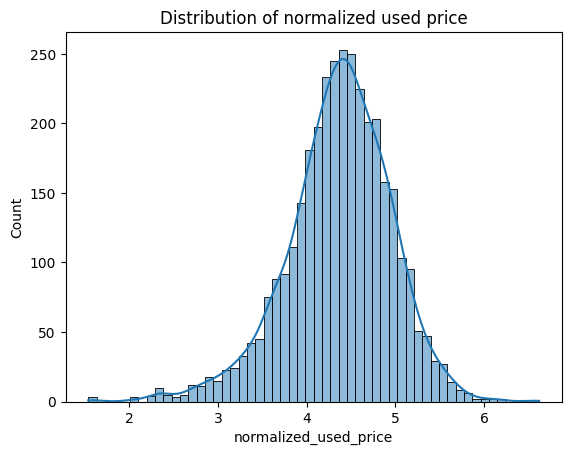

In [9]:
sns.histplot(data=used_phones, x="normalized_used_price", kde=True)
plt.title("Distribution of normalized used price")
plt.show()


In [10]:
used_phones[["normalized_used_price", "normalized_new_price"]].corr()


,normalized_used_price,normalized_new_price
normalized_used_price,1.000000,0.834496
normalized_new_price,0.834496,1.000000


## 5. Prepare features and target

In [11]:
# The model predicts normalized_used_price.
# Keep the target in its original dataset scale; do not standardize it here.
target = "normalized_used_price"

X = used_phones.drop(columns=[target]).copy()
y = used_phones[target].copy()

# Identify categorical and numeric input columns from the raw dataset.
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(exclude=["object", "category", "bool"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns: ['device_brand', 'os', '4g', '5g']
Numeric columns: ['screen_size', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_new_price']


In [22]:
used_phones.head()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


## 6. Preprocess and train the model

In [12]:
# Numeric columns: fill missing values, then scale.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: fill missing values, then one-hot encode.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['screen_size',
                                                   'rear_camera_mp',
                                                   'front_camera_mp',
                                                   'internal_memory', 'ram',
                                                   'battery', 'weight',
                                                   'release_year', 'days_used',
                                                   'normalized_new_price']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['device_brand', 'os', '4g',
                                                   '5g'])])),
                ('regressor', LinearRegression())])

## 7. Evaluate the model

In [13]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R² score:", round(r2, 4))


MAE: 0.1844
RMSE: 0.2309
R² score: 0.8357


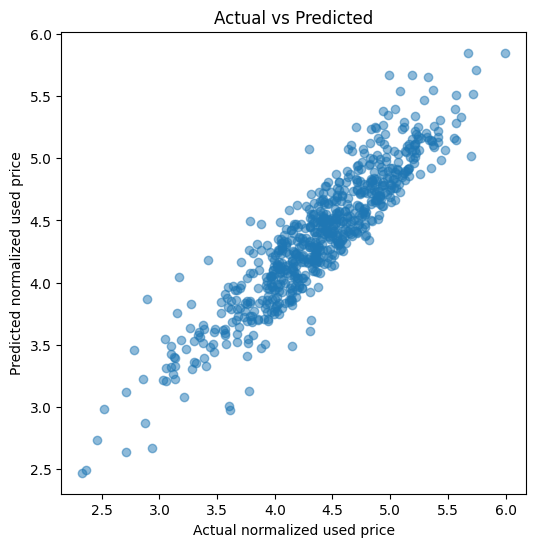

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual normalized used price")
plt.ylabel("Predicted normalized used price")
plt.title("Actual vs Predicted")
plt.show()


## 8. Predict for a new phone

Enter the phone details using the **same columns and category spellings as the dataset**. The example below is only a template: change the values to match a real phone. `normalized_new_price` must be on the same scale as the values in your CSV.

The model output is on the dataset’s natural-log price scale. The final code cell applies `exp()` to return an estimated price in euros (the dataset currency); it does not convert to INR. This inverse assumes the source values were natural-log transformed.


In [ ]:
# Predict on the dataset's normalized (natural-log) price scale.
predicted_normalized_used_price = model.predict(new_phone)[0]
print("Predicted normalized used price:", round(float(predicted_normalized_used_price), 4))

# Convert back to the dataset's original price scale (euros).
predicted_real_price_eur = normalized_to_real_price(predicted_normalized_used_price)
print("Estimated used-device price (EUR):", round(predicted_real_price_eur, 2))
